# Лабораторная работа № 3. Сбор данных через REST API

**Вариант 4:** DummyJSON Posts + Comments → DummyJSON Users.

Цель — собрать данные с пагинацией, нормализовать JSON, выполнить обогащение,
проверить качество и показать инкрементальный повторный запуск.
Основная таблица — комментарии: постов в API только 251, а комментариев 340.
Один комментарий соответствует одной строке, ключ — `comment_id`.
No-code часть выполняется отдельно.

## 1. Настройка

Импортируем библиотеки, задаём параметры запросов и создаём HTTP-сессию.
API публичный, аутентификация не требуется. Все результаты сохраняются рядом с блокнотом.

In [1]:
import json
import random
import time
from datetime import datetime, timezone
from email.utils import parsedate_to_datetime
from pathlib import Path
from uuid import uuid4

import matplotlib.pyplot as plt
import pandas as pd
import requests
from IPython.display import display

BASE_URL = "https://dummyjson.com"
PAGE_SIZE, MAX_RECORDS, MAX_PAGES = 100, 1000, 20
TIMEOUT, PAUSE, MAX_ATTEMPTS = 30, 0.3, 4
OUT = next(p for p in [Path.cwd(), Path.cwd() / "lab_3",
                      Path.cwd() / "Data_mining/lab_3"] if (p / "lab_3.ipynb").exists())

session = requests.Session()
session.headers.update({"User-Agent": "University-Lab3/1.0", "Accept": "application/json"})
log_path = OUT / "collection_log.csv"
logs = pd.read_csv(log_path).to_dict("records") if log_path.exists() else []

## 2. Безопасные запросы и пагинация

Проверяем HTTP-статус, Content-Type и JSON; ошибки содержат первые 200 байт ответа.
Повторяем только 429 и 5xx, максимум четыре попытки, с экспоненциальной задержкой
и джиттером. `Retry-After` учитывается как число секунд или HTTP-дата.
Остальные 4xx и сетевые ошибки завершают сбор. Каждая попытка записывается в журнал.

Пагинация использует `limit/skip`: сдвиг увеличивается на фактическую длину страницы.
Остановка — пустая страница, `total`, `max_records` или `max_pages`.

In [2]:
def parse_response(response):
    preview = response.content[:200].decode("utf-8", errors="replace")
    if not 200 <= response.status_code < 300:
        raise RuntimeError(f"HTTP {response.status_code}: {response.url}; {preview}")
    content_type = response.headers.get("Content-Type", "").split(";")[0].lower()
    if content_type != "application/json" and not content_type.endswith("+json"):
        raise ValueError(f"Ожидался JSON, получен {content_type}: {response.url}; {preview}")
    try:
        return response.json()
    except ValueError as error:
        raise ValueError(f"Некорректный JSON: {response.url}; {preview}") from error


def get_json(resource, params, page, run_id):
    url = f"{BASE_URL}/{resource}"
    for attempt in range(1, MAX_ATTEMPTS + 1):
        time.sleep(PAUSE)
        started = time.perf_counter()
        entry = {"run_id": run_id, "resource": resource, "page": page,
                 "attempt": attempt, "params": json.dumps(params), "url": url,
                 "timestamp": datetime.now(timezone.utc).isoformat(), "records": 0,
                 "status": None, "error": ""}
        try:
            response = session.get(url, params=params, timeout=TIMEOUT)
        except requests.RequestException as error:
            entry.update(duration_s=time.perf_counter() - started, error=str(error))
            logs.append(entry)
            pd.DataFrame(logs).to_csv(log_path, index=False)
            raise
        entry.update(status=response.status_code, url=response.url,
                     duration_s=time.perf_counter() - started,
                     retry_after=response.headers.get("Retry-After", ""),
                     rate_limit_headers=json.dumps({k: v for k, v in response.headers.items()
                                                    if "ratelimit" in k.lower()}))
        retryable = response.status_code == 429 or 500 <= response.status_code < 600
        if retryable and attempt < MAX_ATTEMPTS:
            entry["error"] = response.content[:200].decode("utf-8", errors="replace")
            logs.append(entry)
            pd.DataFrame(logs).to_csv(log_path, index=False)
            delay = 2 ** (attempt - 1) + random.uniform(0, 0.5)
            retry_after = response.headers.get("Retry-After")
            if retry_after:
                try:
                    wait = float(retry_after)
                except ValueError:
                    wait = (parsedate_to_datetime(retry_after)
                            - datetime.now(timezone.utc)).total_seconds()
                delay = max(delay, wait)
            time.sleep(delay)
            continue
        try:
            data = parse_response(response)
            entry["records"] = len(data[resource])
        except (RuntimeError, ValueError, KeyError) as error:
            entry["error"] = str(error)
            raise
        finally:
            logs.append(entry)
            pd.DataFrame(logs).to_csv(log_path, index=False)
        return data


def paginate(resource, run_id, page_size=100, max_records=1000, max_pages=20, params=None):
    if min(page_size, max_records, max_pages) <= 0:
        raise ValueError("Параметры пагинации должны быть положительными")
    records, skip = [], 0
    for page in range(1, max_pages + 1):
        query = {**(params or {}), "limit": min(page_size, max_records - len(records)),
                 "skip": skip, "sortBy": "id", "order": "asc"}
        data = get_json(resource, query, page, run_id)
        with (OUT / "data_raw.jsonl").open("a", encoding="utf-8") as file:
            file.write(json.dumps({"run_id": run_id, "resource": resource, "page": page,
                                   "collected_at": datetime.now(timezone.utc).isoformat(),
                                   "response": data}, ensure_ascii=False) + "\n")
        batch = data[resource]
        records.extend(batch)
        skip += len(batch)
        if not batch or skip >= data["total"] or len(records) >= max_records:
            break
    return records

## 3. Нормализация и обогащение

`json_normalize(sep="_")` разворачивает вложенные объекты. Массив `tags`
разворачиваем через `record_path` и `meta` в таблицу «пост — тег».
Комментарии соединяем с постами, затем с Users для автора комментария и автора поста.
`many_to_one` и сравнение числа строк проверяют, что соединения не размножают комментарии.
Даты рождения приводим к UTC; даты создания постов и комментариев API не предоставляет.

In [3]:
def build_tables(comments, posts, users):
    comments_df = pd.json_normalize(comments, sep="_").rename(columns={
        "id": "comment_id", "body": "comment_text", "postId": "post_id",
        "likes": "comment_likes", "user_id": "commenter_id"})
    comments_df = comments_df[["comment_id", "comment_text", "post_id",
                               "comment_likes", "commenter_id"]]
    posts_df = pd.json_normalize(posts, sep="_").rename(columns={
        "id": "post_id", "title": "post_title", "userId": "post_author_id",
        "reactions_likes": "post_likes", "reactions_dislikes": "post_dislikes",
        "views": "post_views"})
    posts_df = posts_df[["post_id", "post_title", "post_author_id", "post_likes",
                         "post_dislikes", "post_views"]].drop_duplicates("post_id")
    users_df = pd.json_normalize(users, sep="_").rename(columns={
        "firstName": "first_name", "lastName": "last_name", "birthDate": "birth_date"})
    users_df = users_df.drop_duplicates("id")
    users_df["birth_date"] = pd.to_datetime(users_df["birth_date"], format="%Y-%m-%d",
                                            errors="coerce", utc=True)

    tags = pd.json_normalize(posts, record_path="tags", meta=["id", "userId"], sep="_")
    tags = tags.rename(columns={0: "tag", "id": "post_id", "userId": "post_author_id"})
    tags = tags.drop_duplicates(["post_id", "tag"])

    row_counts = {"исходные комментарии": len(comments_df)}
    clean = comments_df.merge(posts_df, on="post_id", how="left", validate="many_to_one")
    row_counts["после Posts"] = len(clean)
    for prefix, key in [("commenter", "commenter_id"), ("post_author", "post_author_id")]:
        lookup = users_df.add_prefix(prefix + "_")
        clean = clean.merge(lookup, on=key, how="left", validate="many_to_one")
        row_counts[f"после Users ({prefix})"] = len(clean)
    if len(set(row_counts.values())) != 1:
        raise ValueError(f"Изменилось число строк при обогащении: {row_counts}")
    for column in clean.columns:
        if column.endswith(("_id", "_likes", "_dislikes", "_views", "_age")):
            clean[column] = pd.to_numeric(clean[column], errors="coerce").astype("Int64")
    clean["comment_text"] = clean["comment_text"].str.strip()
    clean["post_title"] = clean["post_title"].str.strip()
    return clean, posts_df, users_df, tags, row_counts

## 4. Первый прогон и сохранение состояния

Собираем все три ресурса с одинаковой функцией пагинации. Users ограничиваем
полями `id,firstName,lastName,username,age,birthDate`.
В CSV добавляем только комментарии с ID выше сохранённого водяного знака,
удаляем дубликаты по ключу. Состояние обновляем после сохранения таблицы.
При наличии результатов предыдущего запуска они сохраняются.

In [4]:
def run_pipeline():
    started = time.perf_counter()
    run_id = uuid4().hex[:12]
    state_path, clean_path = OUT / "state.json", OUT / "data_clean.csv"
    state = json.loads(state_path.read_text(encoding="utf-8")) if state_path.exists() else {}
    watermark = state.get("last_comment_id", 0)
    if watermark and not clean_path.exists():
        raise FileNotFoundError("state.json существует, но data_clean.csv отсутствует")

    options = dict(page_size=PAGE_SIZE, max_records=MAX_RECORDS, max_pages=MAX_PAGES)
    comments = paginate("comments", run_id, **options)
    posts = paginate("posts", run_id, **options)
    users = paginate("users", run_id, params={
        "select": "id,firstName,lastName,username,age,birthDate"}, **options)
    current, posts_df, users_df, tags, row_counts = build_tables(comments, posts, users)
    duplicate_count = int(current.duplicated("comment_id").sum())
    new = current[current["comment_id"] > watermark]
    old = pd.read_csv(clean_path) if clean_path.exists() else current.iloc[:0]
    new = new[~new["comment_id"].isin(old["comment_id"])]
    clean = pd.concat([old, new], ignore_index=True).drop_duplicates("comment_id")
    for column in clean.columns:
        if column.endswith(("_id", "_likes", "_dislikes", "_views", "_age")):
            clean[column] = pd.to_numeric(clean[column], errors="coerce").astype("Int64")
        elif column.endswith("_birth_date"):
            clean[column] = pd.to_datetime(clean[column], errors="coerce", utc=True)
    clean = clean.sort_values("comment_id").reset_index(drop=True)
    clean.to_csv(clean_path, index=False)
    tags.to_csv(OUT / "post_tags.csv", index=False)
    state_path.write_text(json.dumps({"last_comment_id": max(watermark, int(clean["comment_id"].max())),
                                      "updated_at": datetime.now(timezone.utc).isoformat()},
                                     ensure_ascii=False, indent=2), encoding="utf-8")
    run_log = pd.DataFrame([entry for entry in logs if entry["run_id"] == run_id])
    metrics = {"run_id": run_id, "records_fetched": len(comments), "new_records": len(new),
               "saved_records": len(clean), "posts": len(posts), "users": len(users),
               "comment_pages": int(run_log.loc[run_log["resource"] == "comments", "page"].nunique()),
               "requests": len(run_log), "duplicates_before": duplicate_count,
               "duration_s": round(time.perf_counter() - started, 3)}
    return clean, posts_df, users_df, metrics, row_counts


clean, posts_df, users_df, first_metrics, merge_counts = run_pipeline()
display(pd.Series(first_metrics, name="Первый прогон"))
display(pd.Series(merge_counts, name="Строк при соединении"))
display(clean.head())

run_id               1f0e01d20b9e
records_fetched               340
new_records                   340
saved_records                 340
posts                         251
users                         208
comment_pages                   4
requests                       10
duplicates_before               0
duration_s                  6.047
Name: Первый прогон, dtype: object

исходные комментарии         340
после Posts                  340
после Users (commenter)      340
после Users (post_author)    340
Name: Строк при соединении, dtype: int64

,comment_id,comment_text,post_id,comment_likes,commenter_id,post_title,post_author_id,post_likes,post_dislikes,post_views,commenter_first_name,commenter_last_name,commenter_username,commenter_age,commenter_birth_date,post_author_first_name,post_author_last_name,post_author_username,post_author_age,post_author_birth_date
0,1,This is some awesome thinking!,242,3,105,The serene meadow stretched to the horizon,60,142,34,1197,Emma,Wilson,emmac,32,1993-06-02 00:00:00+00:00,Lillian,Simmons,lillians,33,1992-03-09 00:00:00+00:00
1,2,What terrific math skills you're showing!,46,4,183,"The clowns had taken over. And yes, they were ...",132,597,23,3730,Cameron,Perez,cameronp,34,1991-09-02 00:00:00+00:00,Zoe,Bennett,zoec,29,1996-05-11 00:00:00+00:00
2,3,You are an amazing writer!,235,2,1,The bustling city market was a feast for the s...,88,1457,15,3074,Emily,Johnson,emilys,29,1996-05-30 00:00:00+00:00,Aubrey,Wagner,aubreyw,31,1994-04-01 00:00:00+00:00
3,4,Wow! You have improved so much!,31,1,89,It was just a burger.,168,443,21,1656,Brayden,Fleming,braydenf,33,1992-07-20 00:00:00+00:00,Luna,Perez,lunah,27,1998-10-08 00:00:00+00:00
4,5,Nice idea!,212,1,149,The ancient ruins whispered tales of the past,130,603,38,3061,Wyatt,Perry,wyattp,35,1990-05-23 00:00:00+00:00,Chloe,Roberts,chloep,42,1983-04-08 00:00:00+00:00


## 5. Качество данных

Для каждого поля показываем полноту и тип, считаем дубликаты. Проверяем
неотрицательность счётчиков, существование постов и авторов, непустой текст
и даты рождения не позже текущей даты. Числовые выбросы ищем методом IQR;
такие наблюдения оставляем, поскольку высокая активность может быть допустимой.

In [5]:
quality = pd.DataFrame({"field": clean.columns,
                        "completeness_pct": (clean.notna().mean() * 100).round(2).values,
                        "dtype": clean.dtypes.astype(str).values})
quality.to_csv(OUT / "quality.csv", index=False)
display(quality)
print("Дубликаты до удаления:", first_metrics["duplicates_before"])
print("Дубликаты в итоговой таблице:", clean.duplicated("comment_id").sum())

counts = ["comment_likes", "post_likes", "post_dislikes", "post_views"]
now = pd.Timestamp.now(tz="UTC")
rules = {
    "Счётчики заполнены и неотрицательны": clean[counts].notna().all(axis=1)
        & clean[counts].ge(0).fillna(False).all(axis=1),
    "Комментарий связан с существующим постом": clean["post_id"].isin(posts_df["post_id"]),
    "Авторы существуют в Users": clean["commenter_id"].isin(users_df["id"])
        & clean["post_author_id"].isin(users_df["id"]),
    "Текст комментария не пуст": clean["comment_text"].fillna("").str.len().gt(0),
    "Даты рождения не в будущем": clean["commenter_birth_date"].le(now)
        & clean["post_author_birth_date"].le(now),
}
checks = pd.DataFrame([{"check": name, "violations": int((~valid).sum())}
                       for name, valid in rules.items()])
checks.to_csv(OUT / "business_checks.csv", index=False)
display(checks)

outlier_rows = []
for field, values in [("comment_likes", clean["comment_likes"]),
                      ("post_likes", posts_df["post_likes"]),
                      ("post_dislikes", posts_df["post_dislikes"]),
                      ("post_views", posts_df["post_views"])]:
    q1, q3 = values.quantile([0.25, 0.75])
    low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    outlier_rows.append({"field": field, "lower": low, "upper": high,
                         "outliers": int(((values < low) | (values > high)).sum())})
outliers = pd.DataFrame(outlier_rows)
outliers.to_csv(OUT / "outliers.csv", index=False)
display(outliers)

,field,completeness_pct,dtype
0,comment_id,100.0,Int64
1,comment_text,100.0,str
2,post_id,100.0,Int64
3,comment_likes,100.0,Int64
4,commenter_id,100.0,Int64
5,post_title,100.0,str
6,post_author_id,100.0,Int64
7,post_likes,100.0,Int64
8,post_dislikes,100.0,Int64
9,post_views,100.0,Int64


Дубликаты до удаления: 0
Дубликаты в итоговой таблице: 0


,check,violations
0,Счётчики заполнены и неотрицательны,0
1,Комментарий связан с существующим постом,0
2,Авторы существуют в Users,0
3,Текст комментария не пуст,0
4,Даты рождения не в будущем,0


,field,lower,upper,outliers
0,comment_likes,-7.00,17.00,0
1,post_likes,-912.00,2116.00,0
2,post_dislikes,-28.00,76.00,0
3,post_views,-2546.75,7331.25,0


## 6. Активность авторов и связь комментариев с реакциями

Считаем комментарии и их лайки на пост, включая посты без комментариев.
Реакции постов учитываем один раз на пост, а не суммируем повторённые значения
из основной таблицы. Для авторов считаем число постов, написанных и полученных
комментариев. Строим графики и вычисляем корреляцию числа комментариев с лайками поста.

,id,first_name,last_name,username,written_comments,posts_count,received_comments,post_likes_sum
82,83,Dylan,Wells,dylanw,7,3,6,2181
38,39,Lucas,Gray,lucasg,6,0,0,0
24,25,Harper,Kelly,harpere,5,0,0,0
13,14,Charlotte,Lopez,charlottem,5,0,0,0
50,51,Eli,Bennett,elib,5,3,9,2483
73,74,Penelope,Harper,penelopeh,5,1,0,1
56,57,Nathan,Dixon,nathand,4,2,2,986
17,18,Logan,Torres,logant,4,3,2,1765
145,146,Leah,Hughes,leahp,4,0,0,0
167,168,Luna,Perez,lunah,4,1,3,443


Корреляция числа комментариев и лайков поста: -0.038


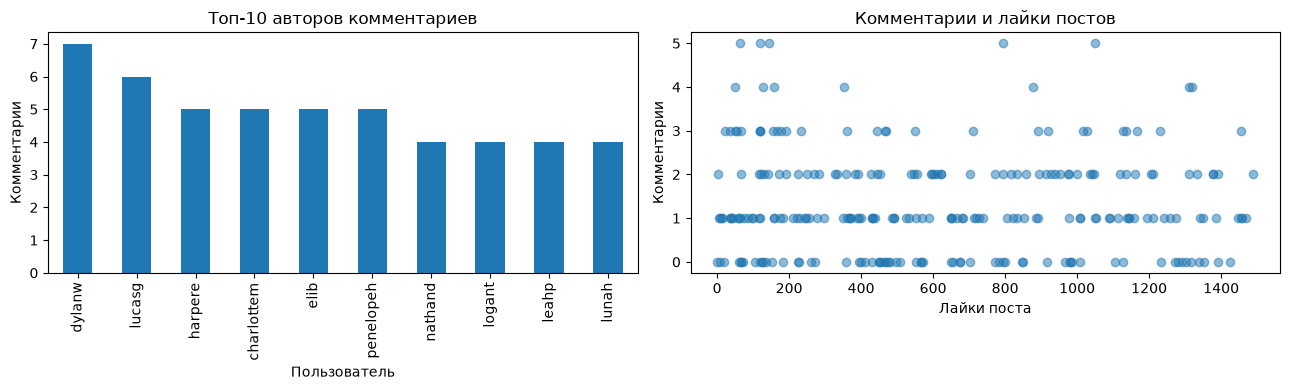

In [6]:
comment_stats = clean.groupby("post_id").agg(
    comments_count=("comment_id", "count"), comment_likes_sum=("comment_likes", "sum"))
posts_activity = posts_df.merge(comment_stats, on="post_id", how="left", validate="one_to_one")
posts_activity[["comments_count", "comment_likes_sum"]] = posts_activity[
    ["comments_count", "comment_likes_sum"]].fillna(0).astype(int)
posts_activity.to_csv(OUT / "posts_activity.csv", index=False)

written = clean.groupby("commenter_id").size().rename("written_comments")
authored = posts_activity.groupby("post_author_id").agg(
    posts_count=("post_id", "count"), received_comments=("comments_count", "sum"),
    post_likes_sum=("post_likes", "sum"))
authors_activity = users_df[["id", "first_name", "last_name", "username"]].merge(
    written, left_on="id", right_index=True, how="left", validate="one_to_one").merge(
    authored, left_on="id", right_index=True, how="left", validate="one_to_one")
activity_fields = ["written_comments", "posts_count", "received_comments", "post_likes_sum"]
authors_activity[activity_fields] = authors_activity[activity_fields].fillna(0).astype(int)
authors_activity = authors_activity.sort_values("written_comments", ascending=False)
authors_activity.to_csv(OUT / "authors_activity.csv", index=False)
display(authors_activity.head(10))
correlation = posts_activity["comments_count"].corr(posts_activity["post_likes"])
print(f"Корреляция числа комментариев и лайков поста: {correlation:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
authors_activity.head(10).plot.bar(x="username", y="written_comments", ax=axes[0], legend=False)
axes[0].set(title="Топ-10 авторов комментариев", xlabel="Пользователь", ylabel="Комментарии")
axes[1].scatter(posts_activity["post_likes"], posts_activity["comments_count"], alpha=0.5)
axes[1].set(title="Комментарии и лайки постов", xlabel="Лайки поста", ylabel="Комментарии")
fig.tight_layout()
fig.savefig(OUT / "activity.png", dpi=150)
plt.show()

## 7. Инкрементальный повторный запуск

Повторяем реальные запросы, читаем `state.json` и измеряем число новых записей.
При неизменном API ожидаем ноль добавлений и прежнее число строк без дубликатов.
Водяной знак по ID рассчитан на добавление записей с возрастающим идентификатором;
изменения и удаления старых комментариев он не отслеживает.

In [7]:
second_clean, _, _, second_metrics, _ = run_pipeline()
metrics = pd.DataFrame([first_metrics, second_metrics])
metrics.to_csv(OUT / "run_metrics.csv", index=False)
display(metrics)
print("Изменение числа строк:", len(second_clean) - len(clean))
print("Новые записи во втором прогоне:", second_metrics["new_records"])
print("Дубликаты после повторного запуска:", second_clean.duplicated("comment_id").sum())
display(pd.DataFrame(logs).tail())
session.close()

,run_id,records_fetched,new_records,saved_records,posts,users,comment_pages,requests,duplicates_before,duration_s
0,1f0e01d20b9e,340,340,340,251,208,4,10,0,6.047
1,74b450ed2622,340,0,340,251,208,4,10,0,5.460


Изменение числа строк: 0
Новые записи во втором прогоне: 0
Дубликаты после повторного запуска: 0


,run_id,resource,page,attempt,params,url,timestamp,records,status,error,duration_s,retry_after,rate_limit_headers
15,74b450ed2622,posts,2,1,"{""limit"": 100, ""skip"": 100, ""sortBy"": ""id"", ""o...",https://dummyjson.com/posts?limit=100&skip=100...,2026-10-02T05:46:36.583165+00:00,100,200,,0.311929,,"{""x-ratelimit-limit"": ""100"", ""x-ratelimit-rema..."
16,74b450ed2622,posts,3,1,"{""limit"": 100, ""skip"": 200, ""sortBy"": ""id"", ""o...",https://dummyjson.com/posts?limit=100&skip=200...,2026-10-02T05:46:37.198401+00:00,51,200,,0.217148,,"{""x-ratelimit-limit"": ""100"", ""x-ratelimit-rema..."
17,74b450ed2622,users,1,1,"{""select"": ""id,firstName,lastName,username,age...",https://dummyjson.com/users?select=id%2CfirstN...,2026-10-02T05:46:37.717557+00:00,100,200,,0.220724,,"{""x-ratelimit-limit"": ""100"", ""x-ratelimit-rema..."
18,74b450ed2622,users,2,1,"{""select"": ""id,firstName,lastName,username,age...",https://dummyjson.com/users?select=id%2CfirstN...,2026-10-02T05:46:38.241217+00:00,100,200,,0.216395,,"{""x-ratelimit-limit"": ""100"", ""x-ratelimit-rema..."
19,74b450ed2622,users,3,1,"{""select"": ""id,firstName,lastName,username,age...",https://dummyjson.com/users?select=id%2CfirstN...,2026-10-02T05:46:38.760283+00:00,8,200,,0.215540,,"{""x-ratelimit-limit"": ""100"", ""x-ratelimit-rema..."


## 8. Вывод

Собрана таблица комментариев с постами, реакциями и авторами; выполнены проверки
качества и анализ активности. Итоговые показатели отображены выше и сохранены
в CSV. Повторный сбор использует файл состояния и не добавляет уже сохранённые ID.
DummyJSON содержит синтетические данные: найденные связи описывают учебный набор,
их нельзя переносить на поведение реальных пользователей или трактовать как причинность.

Источники: [Comments](https://dummyjson.com/docs/comments),
[Posts](https://dummyjson.com/docs/posts), [Users](https://dummyjson.com/docs/users),
[pandas.json_normalize](https://pandas.pydata.org/docs/reference/api/pandas.json_normalize.html),
[Requests](https://requests.readthedocs.io/en/latest/user/advanced/).